# 4 · FAPAR cube, zones and mobility

**Question:** how do vegetation signals (FAPAR) and CDR mobility move together across Senegal's zones?

The cube `fapar_half_month.zarr` is already aggregated to the **CDR half-month periods** (`cdr_period`, `lat`, `lon`)
with four statistics per cell: `FAPAR_mean`, `FAPAR_min`, `FAPAR_max`, `FAPAR_std`.

| Section | Output |
|---|---|
| 1 · Load | cube (with `cdr_period` converted to dates), zones, settings |
| 2 · Grid maps | four statistics side by side · time slices · seasonal climatology · variability |
| 3 · Zonal maps | xvec zonal statistics for all four variables · zone maps · zone time series with min–max and ±std bands |
| 4 · Calendar | holidays, religious festivals, Ramadan, school vacations (switch: `SHOW_EVENTS`) |
| 5 · Mobility × FAPAR | all metrics in `METRICS` · maps · **sliding-window** smoothed series with events · national view · rolling, lagged and best-lag correlation |
| 6 · Anomalies | de-seasonalised series · year-to-year comparison |

> Everything is driven by the settings cell; figures are saved to `fig/` next to this notebook. Mobility is read with Parquet filters (one subset, weighting and window),
> so the ~17 M-row table is never loaded whole. Co-occurrence and correlation here are **descriptive**, not causal.

## 1 · Settings and data

In [1]:
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xvec  # registers the .xvec accessor
import shapely
from matplotlib.colors import Normalize
from shapely.geometry import box

REPO = Path("/data/sahel_cube/dvcube/cube_example")
sys.path.insert(0, str(REPO / "plot_utils"))
from adaptive_cube_plot import plot_time_slices, plot_zonal_maps, plot_zonal_timeseries

# ----------------------------------------------------------------- settings
STORE = REPO / "fapar_halfmonth.zarr"
TIME_DIM = "cdr_period"                    # time dimension in the store
STATS = ["FAPAR_mean", "FAPAR_min", "FAPAR_max", "FAPAR_std"]
MAIN = "FAPAR_mean"                       # variable used for the mobility comparison
ZONE_FILE = "/data/sahel_cube/mobility_data/spatial_units_with_lat_lon.parquet"
START_DATE, END_DATE = None, None          # e.g. "2013-01-01", "2015-12-31"

MOBILITY_FILE = "/data/sahel_cube/mobility_data/mobility_data_processed.parquet"
METRICS = ["rate_depart", "N_depart", "N_return", "N_migrants"]   # any of: N_depart, rate_depart, N_return,
                                                                   # rate_return, N_migrants, rate_migrants
METRIC = METRICS[0]                        # main metric for single-metric outputs
FLOW = "origin"                            # "origin" (departures from a zone) or "destination"
SUBSET, WEIGHT, SPAN = "A", "unweighted", "20days"   # 20days covers every CDR half-month

SMOOTH_WINDOW = 3      # sliding window (half-months) for smoothing; 3 ≈ 1.5 months
CORR_WINDOW = 8        # sliding window (half-months) for rolling correlation; 8 ≈ 4 months
MAX_LAG = 6            # lagged correlation: ± half-months
SELECTED_IDS = None    # e.g. ["sen.1.1.1", "sen.10.2.4"]; None = low / median / high FAPAR zones

MAP_CONTEXT = True     # coastlines/borders (Natural Earth is downloaded once)
SAVE_FIGS = True       # PNGs go to a "fig" folder next to this notebook
FIG_DIR = Path.cwd() / "fig"
FIG_DPI = 200

# Calendar events (holidays, religious festivals, school vacations) on time-series plots
SHOW_EVENTS = True                          # master switch: False = no event markers anywhere
EVENT_GROUPS = ["muslim", "christian", "civil", "school", "ramadan"]   # drop groups you don't want
LABEL_EVENTS = False                        # small rotated labels (inside the mobility years only)
# Long multi-year axes show only the major festivals; zoomed 2013–2015 plots show every event (see MAJOR_EVENTS below).

CMAPS = {"FAPAR_mean": "YlGn", "FAPAR_min": "YlGn", "FAPAR_max": "YlGn", "FAPAR_std": "PuRd"}

def save(fig, name):
    """Save a figure as fig/<name>.png (next to the notebook) when SAVE_FIGS is True."""
    if SAVE_FIGS and fig is not None:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        path = FIG_DIR / f"{name}.png"
        fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
        print("saved", path.relative_to(Path.cwd()))

In [2]:
# ----------------------------------------------------------------- cube
raw = xr.open_zarr(STORE, consolidated=None)
raw = raw.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon", "y": "lat", "x": "lon"}.items()
                  if k in raw.dims or k in raw.coords})
missing = [v for v in STATS if v not in raw]
if missing:
    raise KeyError(f"{missing} not in store; found {list(raw.data_vars)}")
if TIME_DIM not in raw.dims:
    raise KeyError(f"No {TIME_DIM!r} dimension; found {dict(raw.sizes)}")

def to_datetime(values):
    """cdr_period may be datetimes, 'YYYY-MM-DD' strings or YYYYMMDD integers."""
    v = np.asarray(values)
    if np.issubdtype(v.dtype, np.datetime64):
        return pd.DatetimeIndex(v)
    if np.issubdtype(v.dtype, np.integer):
        return pd.to_datetime(v.astype(str), format="%Y%m%d")
    return pd.to_datetime(v.astype(str))

periods = to_datetime(raw[TIME_DIM].values)
# Plot helpers expect a `time` dimension; the original label is kept as a coordinate.
ds = (raw[STATS]
      .rename({TIME_DIM: "time"})
      .assign_coords(time=periods, cdr_period=("time", raw[TIME_DIM].values))
      .sortby("time")
      .sel(time=slice(START_DATE, END_DATE)))
for v in STATS:
    ds[v].attrs.setdefault("units", "fraction (0–1)" if v != "FAPAR_std" else "std of fraction")

print(f"{STORE.name}: {dict(ds.sizes)}")
print(f"Periods: {pd.Timestamp(ds.time.values[0]).date()} … {pd.Timestamp(ds.time.values[-1]).date()} "
      f"({ds.sizes['time']} half-months)")
print(ds[STATS].mean(["lat", "lon"]).mean("time").compute().to_pandas().round(3).to_string())

fapar_halfmonth.zarr: {'time': 192, 'lat': 87, 'lon': 124}
Periods: 2011-01-01 … 2018-12-16 (192 half-months)
FAPAR_mean    0.216
FAPAR_min     0.165
FAPAR_max     0.270
FAPAR_std     0.032


In [3]:
# ----------------------------------------------------------------- zones
units_df = pd.read_parquet(ZONE_FILE)
geom = units_df.pop("geometry")
if len(geom) and isinstance(geom.iloc[0], (bytes, bytearray, memoryview)):
    geom = shapely.from_wkb(geom.to_numpy())
units = gpd.GeoDataFrame(units_df, geometry=geom, crs="EPSG:4326").to_crs("EPSG:4326")
if units["norm_id"].duplicated().any():
    raise ValueError("norm_id must be unique")

dx = float(np.median(np.abs(np.diff(ds.lon.values))))
dy = float(np.median(np.abs(np.diff(ds.lat.values))))
footprint = box(float(ds.lon.min()) - dx / 2, float(ds.lat.min()) - dy / 2,
                float(ds.lon.max()) + dx / 2, float(ds.lat.max()) + dy / 2)
units_in = units.loc[units.intersects(footprint)].reset_index(drop=True)
EXTENT = (float(ds.lon.min()) - dx / 2, float(ds.lon.max()) + dx / 2,
          float(ds.lat.min()) - dy / 2, float(ds.lat.max()) + dy / 2)
print(f"Zones intersecting the cube: {len(units_in)} / {len(units)}")

Zones intersecting the cube: 151 / 151


In [4]:
# ----------------------------------------------------------------- small map helpers
import cartopy.crs as ccrs
import cartopy.feature as cfeature
PC = ccrs.PlateCarree()

def _context(ax, outlines=True):
    ax.set_extent(EXTENT, crs=PC)
    if MAP_CONTEXT:
        ax.coastlines("50m", linewidth=.6, color="#35445b")
        ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=.45, edgecolor="#46556a")
    if outlines:
        units_in.boundary.plot(ax=ax, color="#17283d", linewidth=.25, alpha=.6)

def grid_panel(arrays, titles, cmaps, *, shared=False, vmin=None, vmax=None, ncols=2,
               suptitle="", cbar_label="", robust=True, outlines=True, size=4.6):
    """Raster panels. shared=True → one colour scale and colourbar; otherwise one per panel."""
    n = len(arrays); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * 1.25 * ncols, size * nrows), squeeze=False,
                             subplot_kw={"projection": PC}, constrained_layout=True)
    if shared:
        vals = np.concatenate([np.asarray(a).ravel() for a in arrays]); vals = vals[np.isfinite(vals)]
        lo, hi = (np.percentile(vals, [2, 98]) if robust else (vals.min(), vals.max()))
        vmin = lo if vmin is None else vmin; vmax = hi if vmax is None else vmax
    for ax, a, t, cm in zip(axes.flat, arrays, titles, cmaps):
        if shared:
            lo, hi = vmin, vmax
        else:
            v = np.asarray(a); v = v[np.isfinite(v)]
            lo, hi = (np.percentile(v, [2, 98]) if robust and v.size else (np.nanmin(v), np.nanmax(v)))
        m = ax.pcolormesh(a.lon, a.lat, a.values, cmap=cm, vmin=lo, vmax=hi, shading="auto", transform=PC, rasterized=True)
        _context(ax, outlines); ax.set_title(t, fontsize=11)
        if not shared:
            fig.colorbar(m, ax=ax, shrink=.8, pad=.02)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    if shared:
        fig.colorbar(m, ax=list(axes.flat[:n]), orientation="horizontal", shrink=.6, pad=.03, label=cbar_label)
    fig.suptitle(suptitle, fontsize=14)
    return fig, axes

def zone_panel(series_list, titles, cmaps, *, labels=None, ncols=2, suptitle="", robust=True, size=4.6):
    """Choropleths of per-zone values (pandas Series indexed by norm_id), one colour bar each."""
    n = len(series_list); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * 1.25 * ncols, size * nrows), squeeze=False,
                             subplot_kw={"projection": PC}, constrained_layout=True)
    for i, (ax, s, t, cm) in enumerate(zip(axes.flat, series_list, titles, cmaps)):
        g = units_in.assign(value=units_in["norm_id"].map(s))
        v = g["value"].dropna().to_numpy()
        lo, hi = (np.percentile(v, [2, 98]) if robust and v.size > 4 else (v.min(), v.max()))
        if hi <= lo: hi = lo + 1e-9
        g.plot(ax=ax, column="value", cmap=cm, vmin=lo, vmax=hi, edgecolor="white", linewidth=.25,
               missing_kwds={"color": "#d8dde3", "hatch": "///", "edgecolor": "#aab"})
        _context(ax, outlines=False); ax.set_title(t, fontsize=11)
        sm = plt.cm.ScalarMappable(norm=Normalize(lo, hi), cmap=cm)
        fig.colorbar(sm, ax=ax, shrink=.8, pad=.02, label=(labels[i] if labels else ""))
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    fig.suptitle(suptitle, fontsize=14)
    return fig, axes

## 2 · Grid maps

### Four statistics for one half-month
`FAPAR_mean/min/max` share the vegetation colour ramp; `FAPAR_std` (spread *within* the half-month) has its own.
Each panel has its own scale (2nd–98th percentile).

saved fig/grid_four_stats.png


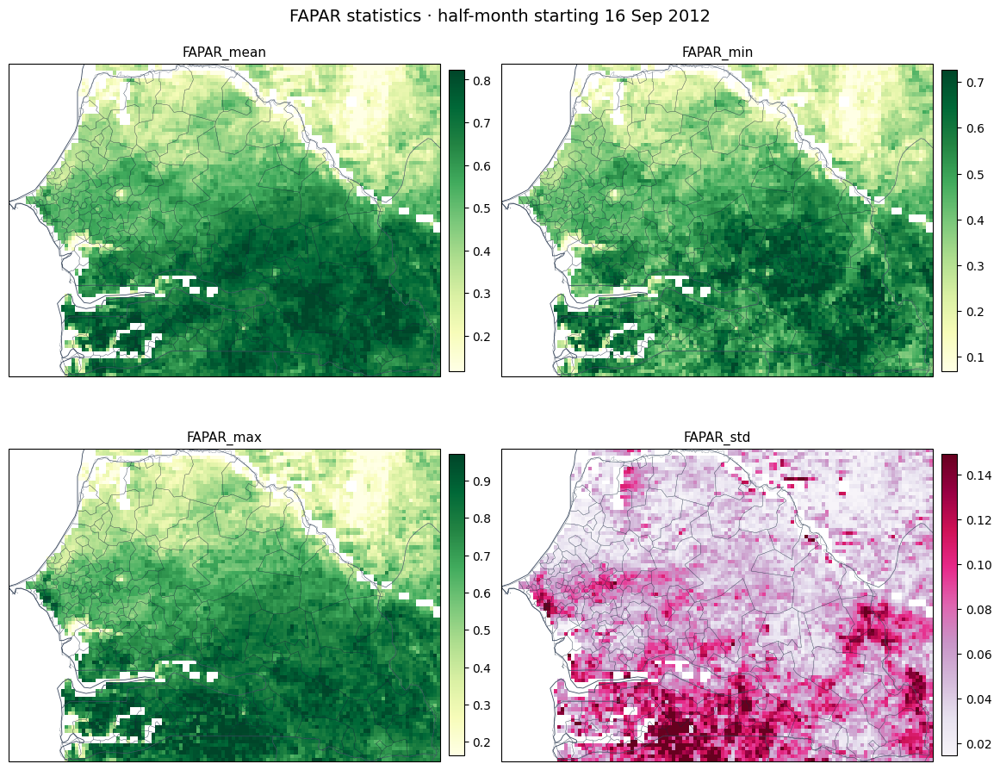

In [5]:
PERIOD = None   # e.g. "2014-09-01"; None = the half-month with the highest national mean FAPAR
if PERIOD is None:
    PERIOD = pd.Timestamp(ds[MAIN].mean(["lat", "lon"]).idxmax("time").values)
PERIOD = pd.Timestamp(ds.time.sel(time=pd.Timestamp(PERIOD), method="nearest").values)
one = ds.sel(time=PERIOD).compute()

fig, _ = grid_panel([one[v] for v in STATS], STATS, [CMAPS[v] for v in STATS],
                    suptitle=f"FAPAR statistics · half-month starting {PERIOD:%d %b %Y}")
save(fig, "grid_four_stats"); plt.show()

### FAPAR_mean through the record
Evenly spaced half-months on **one shared scale**, using `plot_time_slices` from `plot_utils`.

saved fig/grid_time_slices.png


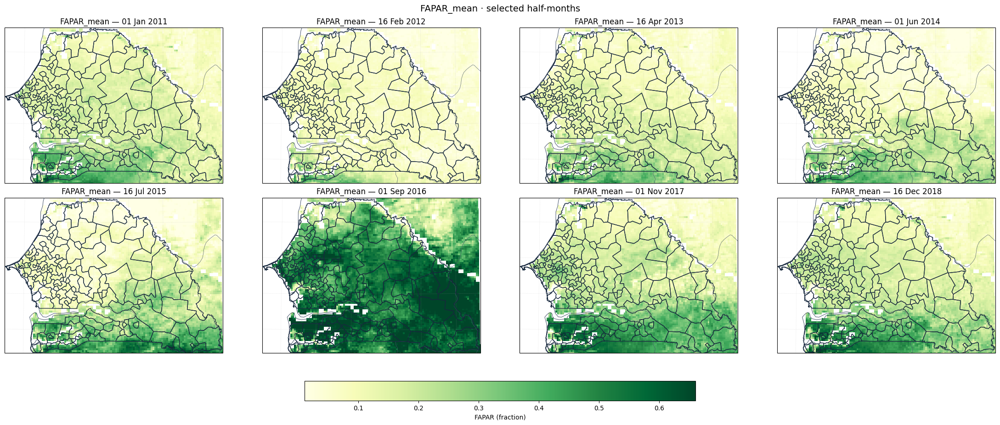

In [6]:
N_SLICES = 8
SLICE_IDX = sorted(set(np.linspace(0, ds.sizes["time"] - 1, N_SLICES).round().astype(int).tolist()))
fig, axes = plot_time_slices(ds, var=MAIN, time_index=SLICE_IDX, boundaries=units_in,
                             cmap=CMAPS[MAIN], robust=True, ncols=4,
                             add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
                             colorbar_label="FAPAR (fraction)", title=f"{MAIN} · selected half-months", show=False)
save(fig, "grid_time_slices"); plt.show()

### Seasonal climatology
Average of `FAPAR_mean` for each calendar month over all years — the green-up of the rainy season (Jul–Oct) stands out.

saved fig/grid_climatology.png


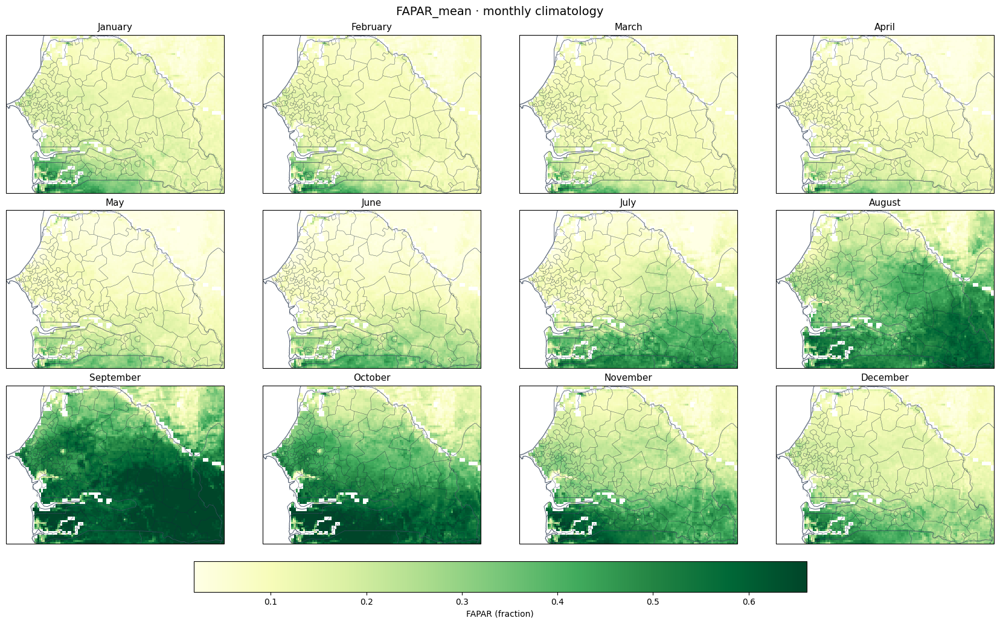

In [7]:
clim = ds[MAIN].groupby("time.month").mean("time").compute()
months = [m for m in range(1, 13) if m in clim.month.values]
fig, _ = grid_panel([clim.sel(month=m) for m in months],
                    [pd.Timestamp(2000, m, 1).strftime("%B") for m in months],
                    [CMAPS[MAIN]] * len(months), shared=True, ncols=4, size=3.4,
                    suptitle=f"{MAIN} · monthly climatology", cbar_label="FAPAR (fraction)")
save(fig, "grid_climatology"); plt.show()

### Where does vegetation vary most?
Left: average of the median, mean and extremes over the record. Right: **between-period** variability (std of `FAPAR_mean`
across half-months) next to **within-period** variability (average `FAPAR_std`) and the average range (`max − min`).

/data/sahel_cube/dvcube/.venv/lib/python3.12/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


saved fig/grid_variability.png


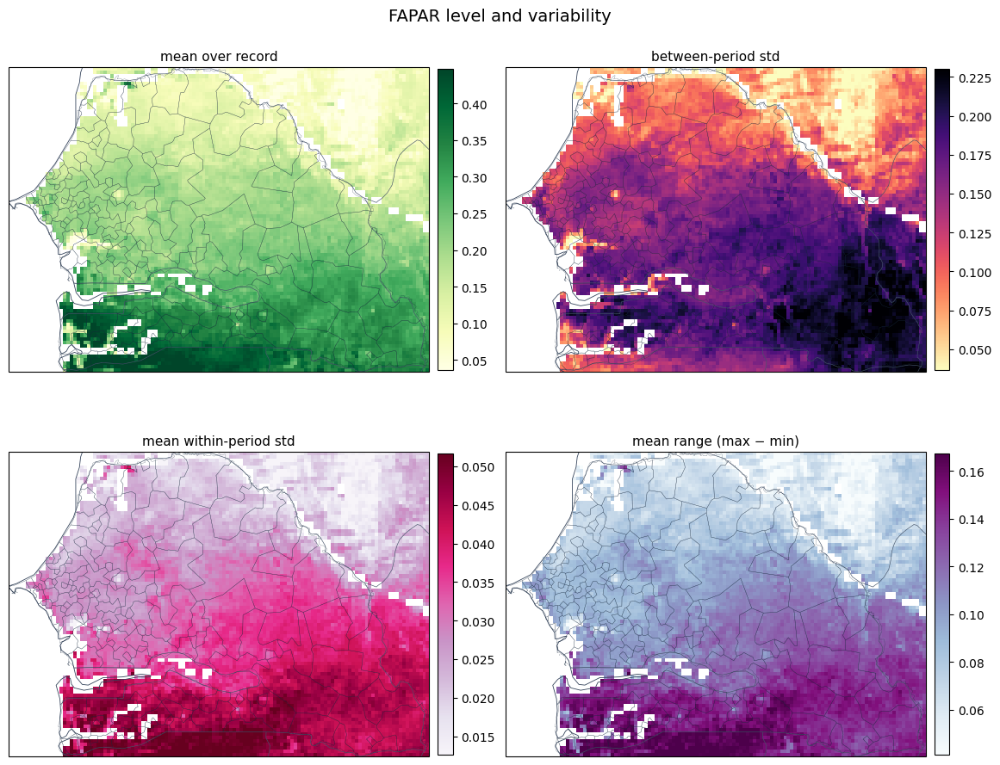

In [8]:
summary = xr.Dataset({
    "mean over record":            ds[MAIN].mean("time"),
    "between-period std":          ds[MAIN].std("time"),
    "mean within-period std":      ds["FAPAR_std"].mean("time"),
    "mean range (max − min)":      (ds["FAPAR_max"] - ds["FAPAR_min"]).mean("time"),
}).compute()
fig, _ = grid_panel([summary[k] for k in summary.data_vars], list(summary.data_vars),
                    ["YlGn", "magma_r", "PuRd", "BuPu"], suptitle="FAPAR level and variability")
save(fig, "grid_variability"); plt.show()

## 3 · Zonal maps (xvec)

All four statistics are reduced to **one value per zone and half-month** in one call.
`exactextract` (fractional pixel coverage) is used when installed, otherwise `rasterize` (cell centres).

In [9]:
try:
    import exactextract  # noqa: F401
    ZONAL_METHOD = "exactextract"
except ImportError:
    ZONAL_METHOD = "rasterize"

zonal = (ds[STATS].drop_vars("cdr_period")
         .rename(lon="x", lat="y")
         .xvec.zonal_stats(geometry=units_in.set_index("norm_id").geometry, x_coords="x", y_coords="y",
                           stats="mean", name="zone", index=True, method=ZONAL_METHOD, all_touched=False)
         .load())
# a plain table (zone × period) used by all later sections
nz, nt = zonal.sizes["zone"], zonal.sizes["time"]
ztab = pd.DataFrame({"norm_id": np.repeat(zonal["norm_id"].values, nt),
                     "period": np.tile(pd.DatetimeIndex(zonal.time.values), nz),
                     **{v: zonal[v].transpose("zone", "time").values.ravel() for v in STATS}})
print(f"method: {ZONAL_METHOD} | zones: {zonal.sizes['zone']} | periods: {zonal.sizes['time']} | "
      f"zones never covered: {int(zonal[MAIN].isnull().all('time').sum())}")
ztab.head()

method: exactextract | zones: 151 | periods: 192 | zones never covered: 0


,norm_id,period,FAPAR_mean,FAPAR_min,FAPAR_max,FAPAR_std
0,sen.1.1.1,2011-01-01,0.244474,0.227547,0.264880,0.009990
1,sen.1.1.1,2011-01-16,0.210590,0.176464,0.264668,0.020282
2,sen.1.1.1,2011-02-01,0.193440,0.124995,0.256750,0.043338
3,sen.1.1.1,2011-02-16,0.225798,0.157881,0.258520,0.030260
4,sen.1.1.1,2011-03-01,0.172623,0.143984,0.188750,0.012853


### Four statistics per zone, same half-month as the grid maps

saved fig/zonal_four_stats.png


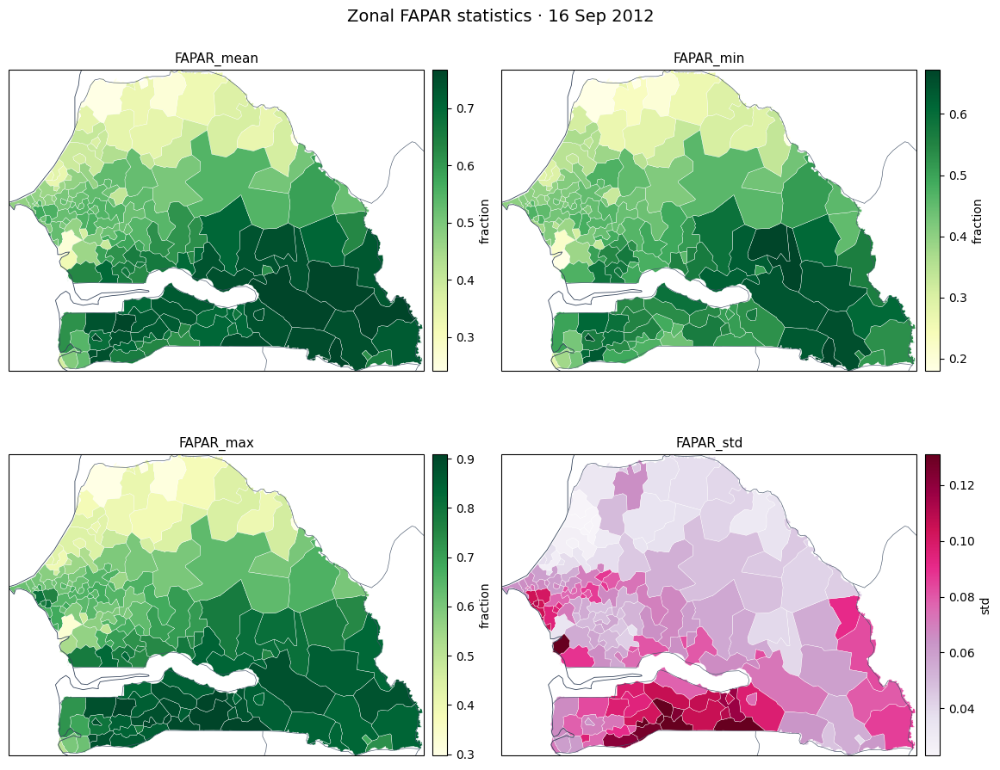

In [10]:
at = ztab[ztab.period == PERIOD].set_index("norm_id")
fig, _ = zone_panel([at[v] for v in STATS], STATS, [CMAPS[v] for v in STATS],
                    labels=["fraction"] * 3 + ["std"],
                    suptitle=f"Zonal FAPAR statistics · {PERIOD:%d %b %Y}")
save(fig, "zonal_four_stats"); plt.show()

### Zonal FAPAR_mean through time (`plot_zonal_maps`) and selected zones (`plot_zonal_timeseries`)

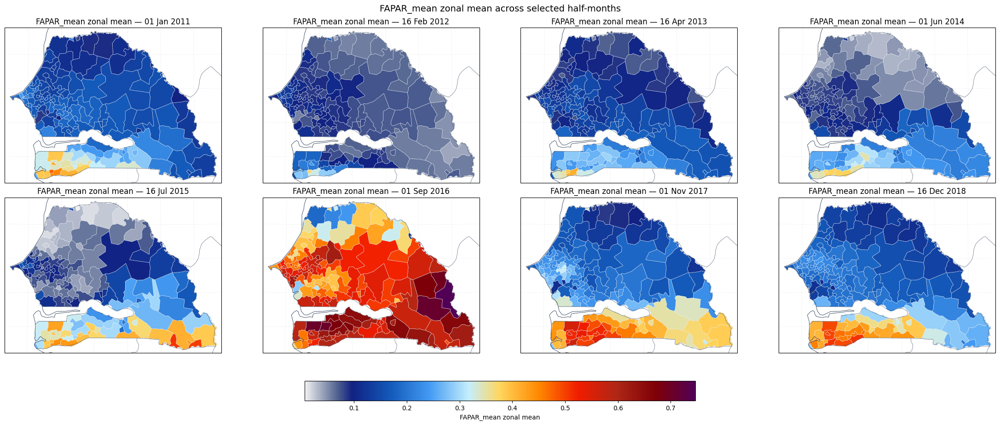

saved fig/zonal_time_slices.png


In [11]:
LABEL = f"{MAIN} zonal mean"
zmain = zonal[MAIN].rename(LABEL)
fig, axes = plot_zonal_maps(zmain, var=LABEL, time_index=SLICE_IDX, ncols=4,
                            add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
                            title=f"{LABEL} across selected half-months")
save(fig, "zonal_time_slices")

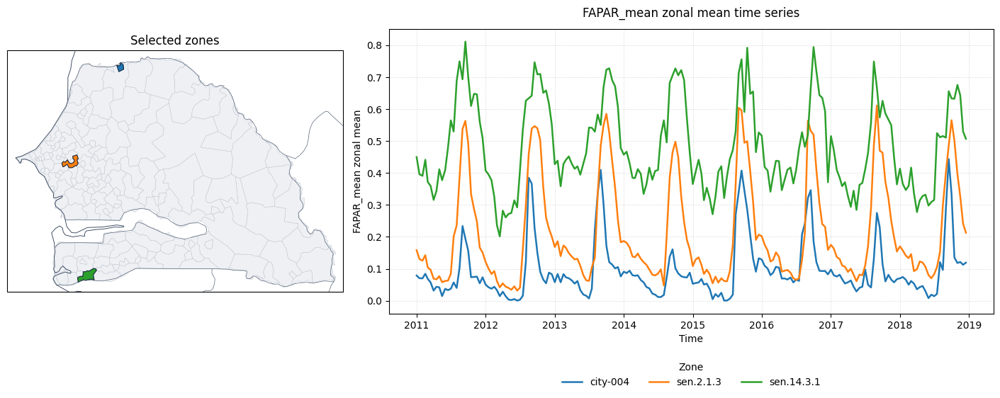

Selected zones: ['city-004', 'sen.2.1.3', 'sen.14.3.1']
saved fig/zonal_timeseries.png


In [12]:
fig, axes = plot_zonal_timeseries(zmain, var=LABEL, zones=SELECTED_IDS, id_coord="norm_id",
                                  add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
                                  title=f"{LABEL} time series")
SELECTED_IDS = list(axes["zones"]) if SELECTED_IDS is None else SELECTED_IDS
print("Selected zones:", SELECTED_IDS)
save(fig, "zonal_timeseries")

### Zone envelopes: mean with min–max range and ±1 std
For each selected zone: zonal `FAPAR_mean` (line), the average of `FAPAR_min`…`FAPAR_max` (light band) and
mean ± `FAPAR_std` (darker band).

saved fig/zonal_envelopes.png


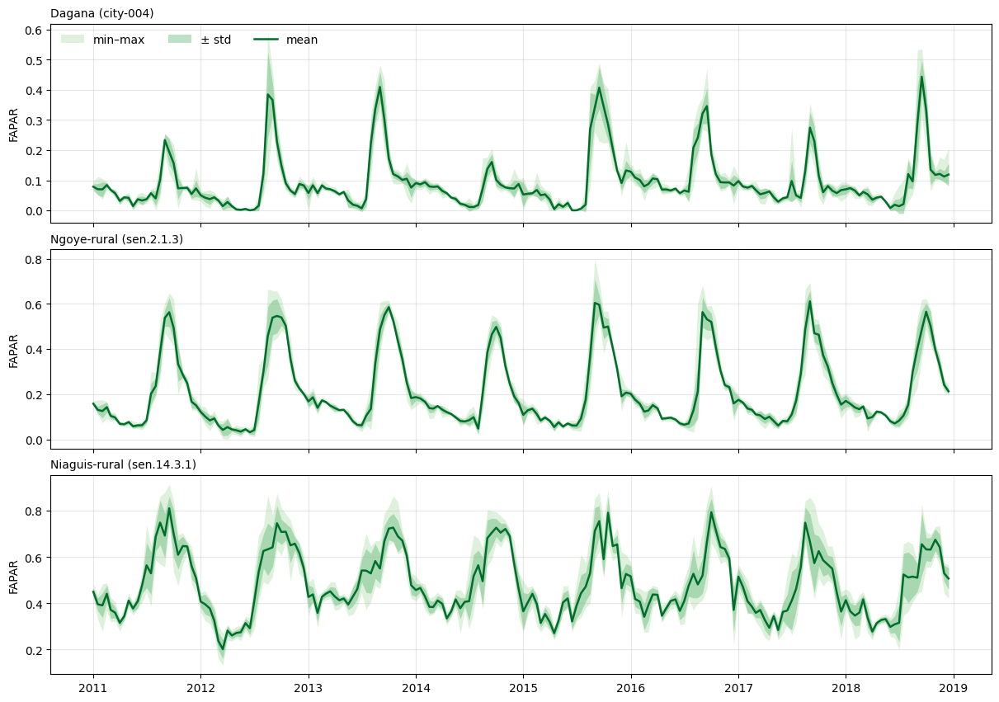

In [13]:
names = units_in.set_index("norm_id")["name"] if "name" in units_in else pd.Series(dtype=str)
fig, axes = plt.subplots(len(SELECTED_IDS), 1, figsize=(12, 2.8 * len(SELECTED_IDS)), sharex=True,
                         constrained_layout=True, squeeze=False)
for ax, zid in zip(axes[:, 0], SELECTED_IDS):
    z = ztab[ztab.norm_id == zid].sort_values("period")
    ax.fill_between(z.period, z.FAPAR_min, z.FAPAR_max, color="#a1d99b", alpha=.35, lw=0, label="min–max")
    ax.fill_between(z.period, z.FAPAR_mean - z.FAPAR_std, z.FAPAR_mean + z.FAPAR_std,
                    color="#41ab5d", alpha=.35, lw=0, label="± std")
    ax.plot(z.period, z.FAPAR_mean, color="#006d2c", lw=1.8, label="mean")
    ax.set_title(f"{names.get(zid, zid)} ({zid})", loc="left", fontsize=10)
    ax.set_ylabel("FAPAR"); ax.grid(alpha=.3)
axes[0, 0].legend(ncol=3, loc="upper left", frameon=False)
save(fig, "zonal_envelopes"); plt.show()

## 4 · Calendar events (holidays, festivals, school vacations)

Mobility in Senegal follows the social and religious calendar as much as the farming calendar. This cell builds an
event table for the whole cube period; time-series plots mark it when `SHOW_EVENTS = True`.

| Group | Events | Dates |
|---|---|---|
| `muslim` | Korité (Eid al-Fitr), Tabaski (Eid al-Adha), Tamkharit (Ashura), Gamou/Maouloud (Mawlid), Grand Magal of Touba (18 Safar) | arithmetic Islamic calendar — within ±1 day of the observed dates |
| `ramadan` | Ramadan (shaded) | 1 Ramadan → day before Korité |
| `christian` | Easter Monday, Ascension, Whit Monday, Assumption, All Saints, Christmas | fixed / computed from Easter |
| `civil` | New Year, Independence Day (4 Apr), Labour Day (1 May) | fixed |
| `school` | Long school vacation (shaded), Christmas and Easter breaks | **approximate** — edit `SCHOOL_BREAKS` to the official calendar |

Exact observance in Senegal can differ by a day (moon sighting, brotherhood announcements); at half-month resolution
this does not matter. Edit or add rows in `EXTRA_EVENTS` (e.g. Magal of Darou Mousty, Popenguine pilgrimage, elections).

In [14]:
from datetime import date, timedelta
from dateutil.easter import easter

def hijri_to_gregorian(y, m, d):
    """Arithmetic (tabular) Islamic calendar → Gregorian date."""
    jd = d + int(29.5 * (m - 1) + 0.99) + (y - 1) * 354 + (3 + 11 * y) // 30 + 1948439.5 - 1
    return date.fromordinal(int(jd - 1721424.5))

# Approximate school breaks (month, day) — adjust to the official calendar for each school year.
SCHOOL_BREAKS = [("Long vacation", (7, 15), (10, 5)),
                 ("Christmas break", (12, 23), (1, 2))]
EXTRA_EVENTS = [   # (date, label, group) — add your own, e.g. ("2014-02-01", "Elections", "civil")
]

def build_events(start, end):
    rows = []
    y0, y1 = start.year - 1, end.year + 1
    for hy in range(int((y0 - 622) * 1.0307) - 2, int((y1 - 622) * 1.0307) + 3):
        for (m, d, label, group) in [(10, 1, "Korité", "muslim"), (12, 10, "Tabaski", "muslim"),
                                     (1, 10, "Tamkharit", "muslim"), (3, 12, "Gamou", "muslim"),
                                     (2, 18, "Magal Touba", "muslim")]:
            rows.append((hijri_to_gregorian(hy, m, d), None, label, group))
        rows.append((hijri_to_gregorian(hy, 9, 1), hijri_to_gregorian(hy, 10, 1) - timedelta(days=1),
                     "Ramadan", "ramadan"))
    for y in range(y0, y1 + 1):
        e = easter(y)
        rows += [(e + timedelta(days=1), None, "Easter Mon.", "christian"),
                 (e + timedelta(days=39), None, "Ascension", "christian"),
                 (e + timedelta(days=50), None, "Whit Mon.", "christian"),
                 (date(y, 8, 15), None, "Assumption", "christian"),
                 (date(y, 11, 1), None, "All Saints", "christian"),
                 (date(y, 12, 25), None, "Christmas", "christian"),
                 (date(y, 1, 1), None, "New Year", "civil"),
                 (date(y, 4, 4), None, "Independence", "civil"),
                 (date(y, 5, 1), None, "Labour Day", "civil"),
                 (e - timedelta(days=3), e + timedelta(days=8), "Easter break", "school")]
        for label, (m0, d0), (m1, d1) in SCHOOL_BREAKS:
            s0 = date(y, m0, d0)
            s1 = date(y + (1 if (m1, d1) < (m0, d0) else 0), m1, d1)
            rows.append((s0, s1, label, "school"))
    for d, label, group in EXTRA_EVENTS:
        rows.append((pd.Timestamp(d).date(), None, label, group))
    ev = pd.DataFrame(rows, columns=["start", "end", "label", "group"])
    ev["start"] = pd.to_datetime(ev["start"]); ev["end"] = pd.to_datetime(ev["end"])
    ev = ev[(ev.start <= end) & (ev.end.fillna(ev.start) >= start)].sort_values("start").reset_index(drop=True)
    return ev

EVENTS = build_events(pd.Timestamp(ds.time.values[0]), pd.Timestamp(ds.time.values[-1]) + pd.Timedelta(days=15))
MAJOR_EVENTS = ["Korité", "Tabaski", "Magal Touba", "Gamou", "Tamkharit"]   # lines shown on long axes
EVENT_STYLE = {   # colour, line style
    "muslim": ("#7b3294", "-"), "christian": ("#2166ac", "--"), "civil": ("#636363", ":"),
    "school": ("#bdbdbd", None), "ramadan": ("#c2a5cf", None),
}

def mark_events(ax, label_window=None, groups=None, legend=False, detail="major"):
    """Draw events on a time axis. Spans (Ramadan, school vacations) are shaded; single days are vertical lines.
    detail="major": only MAJOR_EVENTS as lines (used on long multi-year axes);
    detail="all":   every event in EVENT_GROUPS (used on the zoomed CDR-years plots).
    Labels are written only for events inside `label_window` and never closer than 12 days to the previous one."""
    if not SHOW_EVENTS:
        return
    groups = groups or EVENT_GROUPS
    x0, x1 = ax.get_xlim()
    sel = EVENTS[EVENTS.group.isin(groups)]
    if detail == "major":
        sel = sel[sel.end.notna() | sel.label.isin(MAJOR_EVENTS)]
    last_label = pd.Timestamp("1900-01-01")
    for _, e in sel.iterrows():
        colour, ls = EVENT_STYLE[e.group]
        if pd.notna(e.end):
            ax.axvspan(e.start, e.end, color=colour, alpha=.18 if e.group == "ramadan" else .22, lw=0, zorder=0)
            continue
        ax.axvline(e.start, color=colour, ls=ls, lw=.9, alpha=.75, zorder=1)
        if (LABEL_EVENTS and label_window is not None and label_window[0] <= e.start <= label_window[1]
                and (e.start - last_label).days >= 12):
            ax.text(e.start, .99, " " + e.label, transform=ax.get_xaxis_transform(), rotation=90,
                    va="top", ha="right", fontsize=6.5, color=colour, alpha=.95, clip_on=True)
            last_label = e.start
    ax.set_xlim(x0, x1)
    if legend:
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch
        hs = []
        for g in groups:
            c, ls = EVENT_STYLE[g]
            hs.append(Patch(color=c, alpha=.35, label=g) if ls is None else Line2D([], [], color=c, ls=ls, label=g))
        ax.figure.legend(handles=hs, loc="outside lower center", ncol=len(hs), frameon=False, fontsize=8,
                         title=f"calendar events ({'major only' if detail == 'major' else 'all'})", title_fontsize=8)

print(f"{len(EVENTS)} events between {EVENTS.start.min():%Y-%m-%d} and {EVENTS.start.max():%Y-%m-%d}")
EVENTS[(EVENTS.start >= "2013-01-01") & (EVENTS.start < "2016-01-01") & EVENTS.group.isin(["muslim", "civil"])]

147 events between 2010-12-23 and 2018-12-25


,start,end,label,group
37,2013-01-01,NaT,Magal Touba,muslim
38,2013-01-01,NaT,New Year,civil
39,2013-01-24,NaT,Gamou,muslim
42,2013-04-04,NaT,Independence,civil
43,2013-05-01,NaT,Labour Day,civil
48,2013-08-08,NaT,Korité,muslim
50,2013-10-15,NaT,Tabaski,muslim
52,2013-11-14,NaT,Tamkharit,muslim
53,2013-12-22,NaT,Magal Touba,muslim
56,2014-01-01,NaT,New Year,civil


## 5 · Mobility × FAPAR

### Read and aggregate mobility (only what is needed)
All metrics in `METRICS` are read in one pass, filtered **inside the Parquet reader** (subset, weighting, window), and
summed per zone and CDR period — by origin (`FLOW="origin"`) or by destination.

- `N_depart`, `N_return`, `N_migrants` are **counts** of users; `rate_*` are counts relative to the observed users.
- Summing a rate over destinations gives the origin's total rate.

In [15]:
id_col = "norm_spatial_id_origin" if FLOW == "origin" else "norm_spatial_id_destination"
mob_raw = pd.read_parquet(MOBILITY_FILE, columns=[id_col, "date", *METRICS],
                          filters=[("subset_type", "==", SUBSET), ("weight_type", "==", WEIGHT),
                                   ("days_span", "==", SPAN)])
mob = (mob_raw.groupby([id_col, "date"], observed=True)[METRICS].sum()
       .reset_index().rename(columns={id_col: "norm_id", "date": "period"}))
mob["period"] = pd.to_datetime(mob["period"]).dt.normalize()
del mob_raw

# The CLIMATE time axis is the master: mobility is placed on the cube's periods (gaps where no CDR data).
panel = ztab.merge(mob, on=["norm_id", "period"], how="left")
MOB_WINDOW = (mob.period.min(), mob.period.max() + pd.Timedelta(days=15))
matched = panel.dropna(subset=[METRIC]).period.nunique()
print(f"zone-period rows: {len(mob):,} | climate periods: {ztab.period.nunique()} | periods with mobility: {matched} "
      f"({MOB_WINDOW[0]:%Y-%m-%d} … {MOB_WINDOW[1]:%Y-%m-%d})")
if matched == 0:
    raise ValueError("No CDR period matches the cube's cdr_period values — check both date conventions.")

def mlabel(m):
    return f"{m} ({FLOW}, {SPAN}, subset {SUBSET}, {WEIGHT})"
METRIC_COLORS = dict(zip(["rate_depart", "N_depart", "N_return", "rate_return", "N_migrants", "rate_migrants"],
                         ["#d7301f", "#e6550d", "#3182bd", "#6baed6", "#756bb1", "#9e9ac8"]))
mob.groupby("period")[METRICS].sum().describe().round(3)

zone-period rows: 10,268 | climate periods: 192 | periods with mobility: 68 (2013-01-16 … 2015-12-16)


,rate_depart,N_depart,N_return,N_migrants
count,68.000,68.000,68.000,68.000
mean,3.483,28054.309,27302.235,95849.750
std,1.057,10168.127,8920.557,27523.435
min,2.233,15489.000,18212.000,64805.000
25%,2.652,20606.000,21306.750,72163.500
50%,3.213,24855.500,24649.000,83463.500
75%,4.061,33315.500,29552.750,122508.500
max,6.948,55757.000,59151.000,152183.000


### Side by side: FAPAR and each mobility metric for the same half-month

saved fig/maps_fapar_mobility_20140716.png


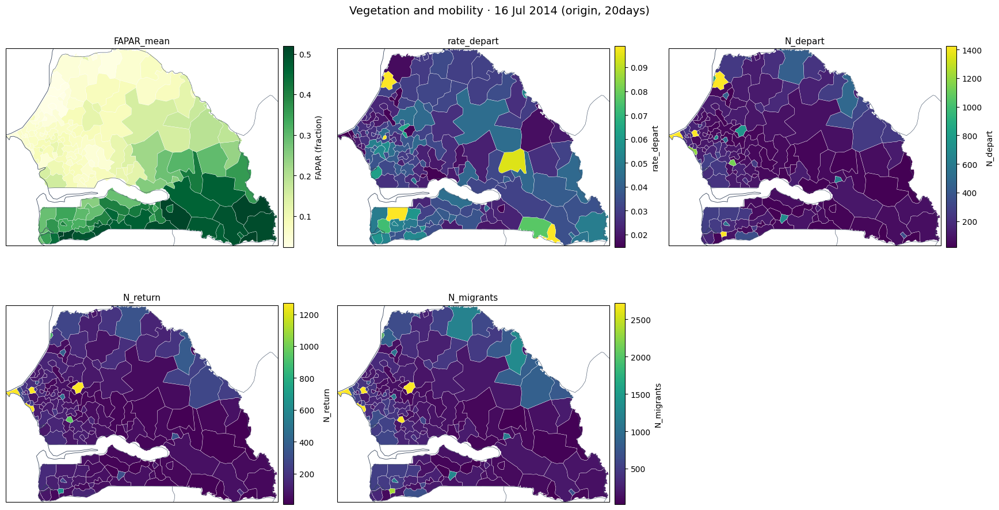

In [16]:
MAP_PERIOD = PERIOD if PERIOD in set(mob.period) else pd.Timestamp(sorted(set(mob.period))[len(set(mob.period)) // 2])
p = panel[panel.period == MAP_PERIOD].set_index("norm_id")
fig, _ = zone_panel([p[MAIN]] + [p[m] for m in METRICS], [MAIN] + METRICS,
                    [CMAPS[MAIN]] + ["viridis"] * len(METRICS),
                    labels=["FAPAR (fraction)"] + METRICS, ncols=min(3, len(METRICS) + 1),
                    suptitle=f"Vegetation and mobility · {MAP_PERIOD:%d %b %Y} ({FLOW}, {SPAN})")
save(fig, f"maps_fapar_mobility_{MAP_PERIOD:%Y%m%d}"); plt.show()

### Sliding-window smoothing — separate panels, with calendar events
For each selected zone: FAPAR (top) and one panel per metric, all on the **climate time axis**.
Faint = raw half-months, bold = centred rolling mean over `SMOOTH_WINDOW` half-months.
On these multi-year axes only the major festivals (`MAJOR_EVENTS`) and shaded periods are drawn; the zoomed plots below show every event. Labels appear inside the mobility years only.

saved fig/smooth_separate_city-004.png


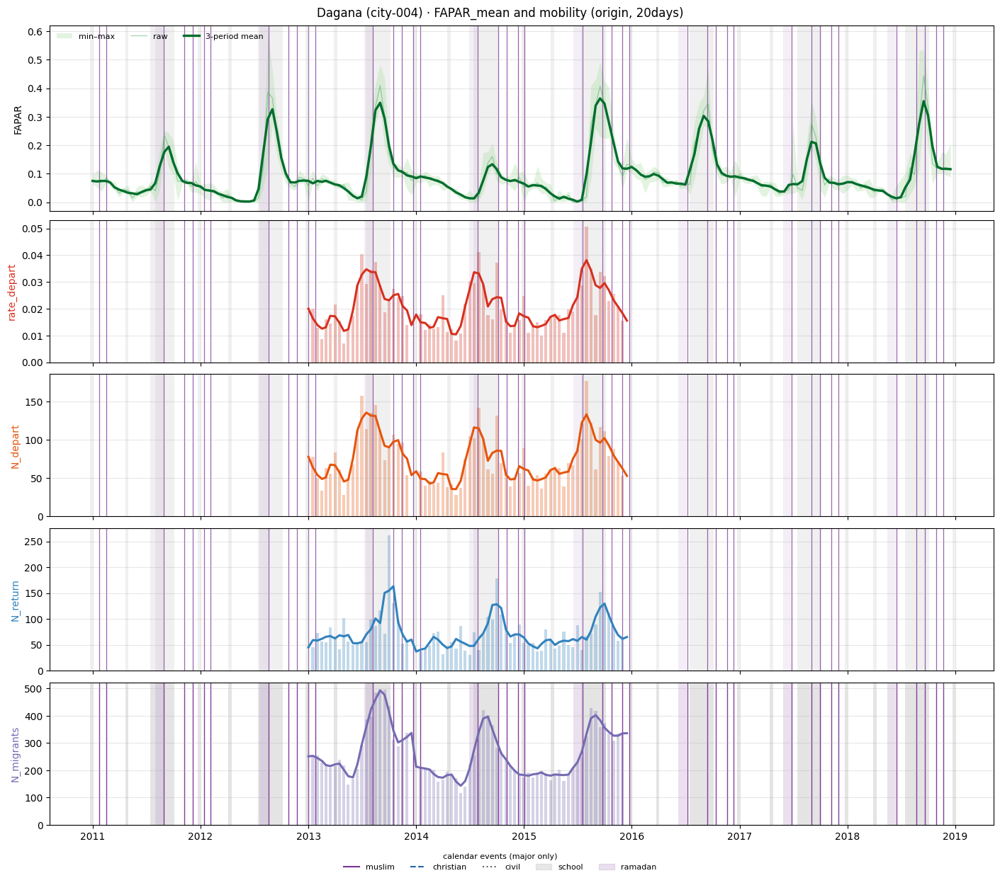

saved fig/smooth_separate_sen.2.1.3.png


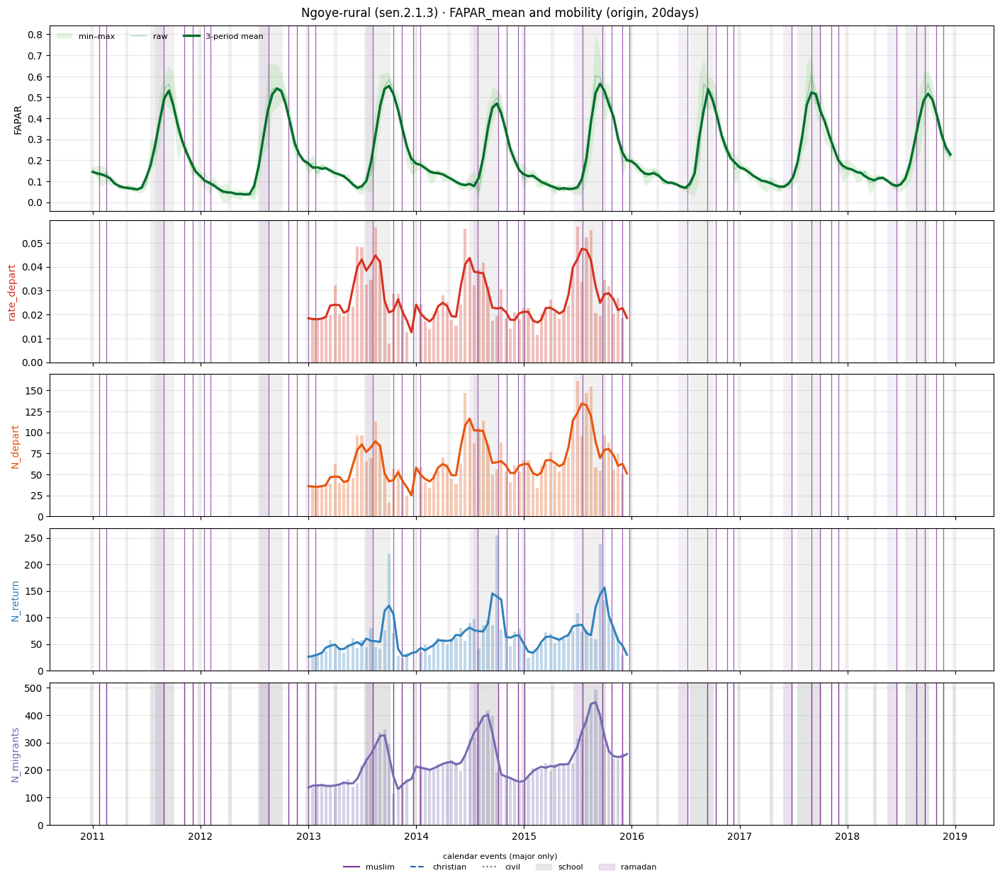

saved fig/smooth_separate_sen.14.3.1.png


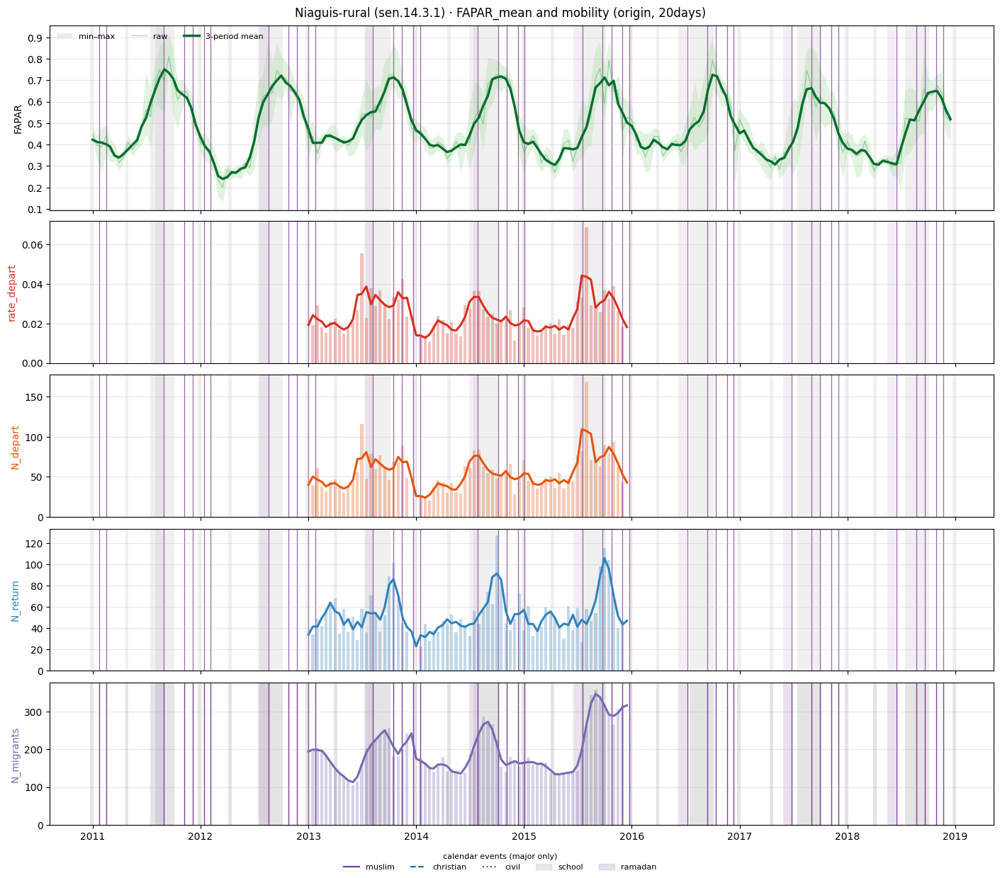

In [17]:
def smooth(s, w=SMOOTH_WINDOW):
    return s.rolling(w, center=True, min_periods=max(1, w // 2)).mean()

for zid in SELECTED_IDS:
    z = panel[panel.norm_id == zid].sort_values("period").set_index("period")
    fig, axs = plt.subplots(1 + len(METRICS), 1, figsize=(14, 2.3 * (1 + len(METRICS)) + 0.8), sharex=True,
                            constrained_layout=True, gridspec_kw={"height_ratios": [1.3] + [1] * len(METRICS)})
    a1 = axs[0]
    a1.fill_between(z.index, z.FAPAR_min, z.FAPAR_max, color="#a1d99b", alpha=.3, lw=0, label="min–max")
    a1.plot(z.index, z[MAIN], color="#41ab5d", lw=1, alpha=.45, label="raw")
    a1.plot(z.index, smooth(z[MAIN]), color="#006d2c", lw=2.4, label=f"{SMOOTH_WINDOW}-period mean")
    a1.set_ylabel("FAPAR"); a1.grid(alpha=.3); a1.legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
    for ax, m in zip(axs[1:], METRICS):
        c = METRIC_COLORS.get(m, "#d7301f")
        ax.bar(z.index, z[m], width=10, color=c, alpha=.3)
        ax.plot(z.index, smooth(z[m]), color=c, lw=2.2)
        ax.set_ylabel(m, color=c); ax.grid(alpha=.3)
    for ax in axs:
        mark_events(ax, label_window=MOB_WINDOW if ax is axs[1] else None)
    mark_events(axs[-1], legend=True)
    fig.suptitle(f"{names.get(zid, zid)} ({zid}) · {MAIN} and mobility ({FLOW}, {SPAN})", fontsize=12)
    save(fig, f"smooth_separate_{zid}"); plt.show()

### The same, zoomed to the mobility years
Easier to read the event labels: only 2013–2015 (the CDR period), FAPAR and all metrics standardised (z-scores within
the zone and window) on one axis.

saved fig/zoom_events_city-004.png


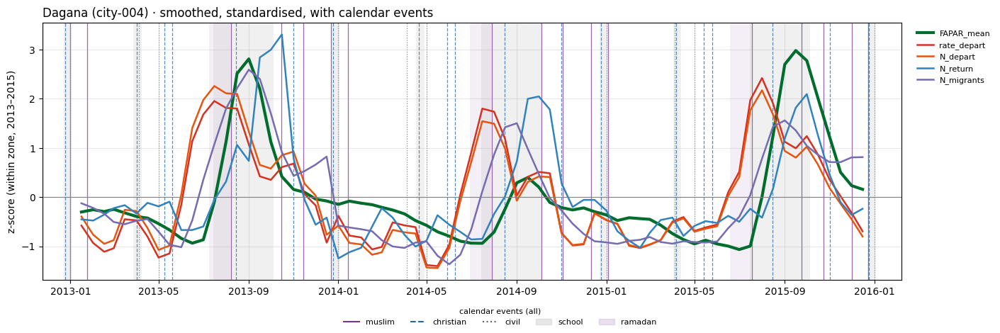

saved fig/zoom_events_sen.2.1.3.png


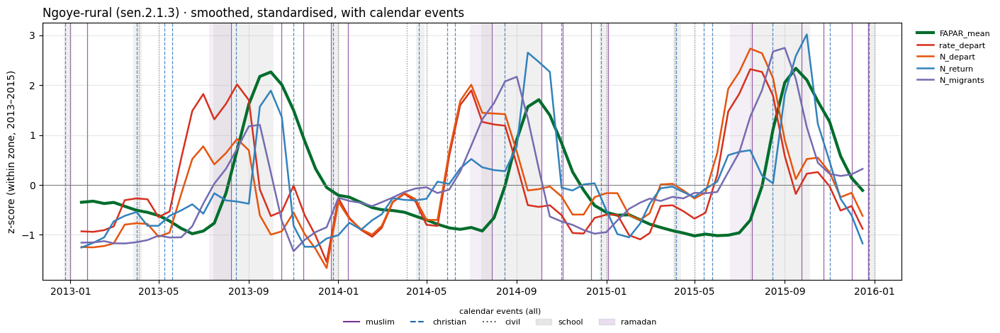

saved fig/zoom_events_sen.14.3.1.png


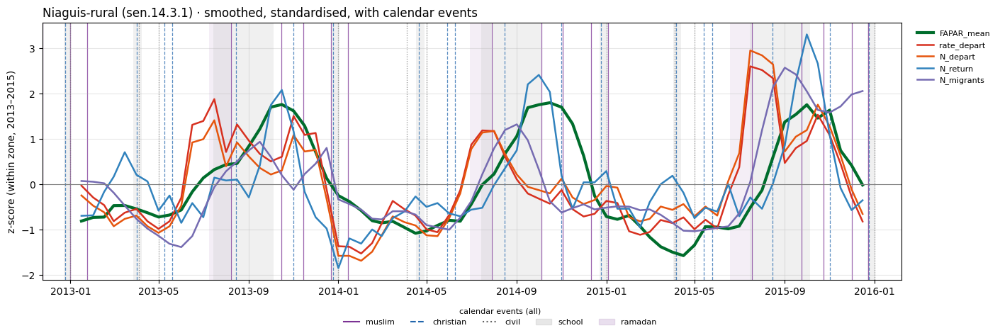

In [18]:
def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

for zid in SELECTED_IDS:
    z = panel[(panel.norm_id == zid) & panel.period.between(*MOB_WINDOW)].sort_values("period").set_index("period")
    fig, ax = plt.subplots(figsize=(14, 4.6), constrained_layout=True)
    ax.plot(z.index, zscore(smooth(z[MAIN])), color="#006d2c", lw=3, label=f"{MAIN}")
    for m in METRICS:
        ax.plot(z.index, zscore(smooth(z[m])), color=METRIC_COLORS.get(m), lw=1.8, label=m)
    ax.axhline(0, color="grey", lw=.8); ax.grid(alpha=.3); ax.set_ylabel("z-score (within zone, 2013–2015)")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    mark_events(ax, label_window=MOB_WINDOW, legend=True, detail="all")
    ax.set_title(f"{names.get(zid, zid)} ({zid}) · smoothed, standardised, with calendar events", loc="left")
    save(fig, f"zoom_events_{zid}"); plt.show()

### Together on one climate time axis (per metric)
Left: two y-axes (FAPAR left, mobility right). Right: both as z-scores — note FAPAR is standardised over its
whole record and mobility over the CDR years, so compare **timing**, not height.

saved fig/smooth_together_rate_depart.png


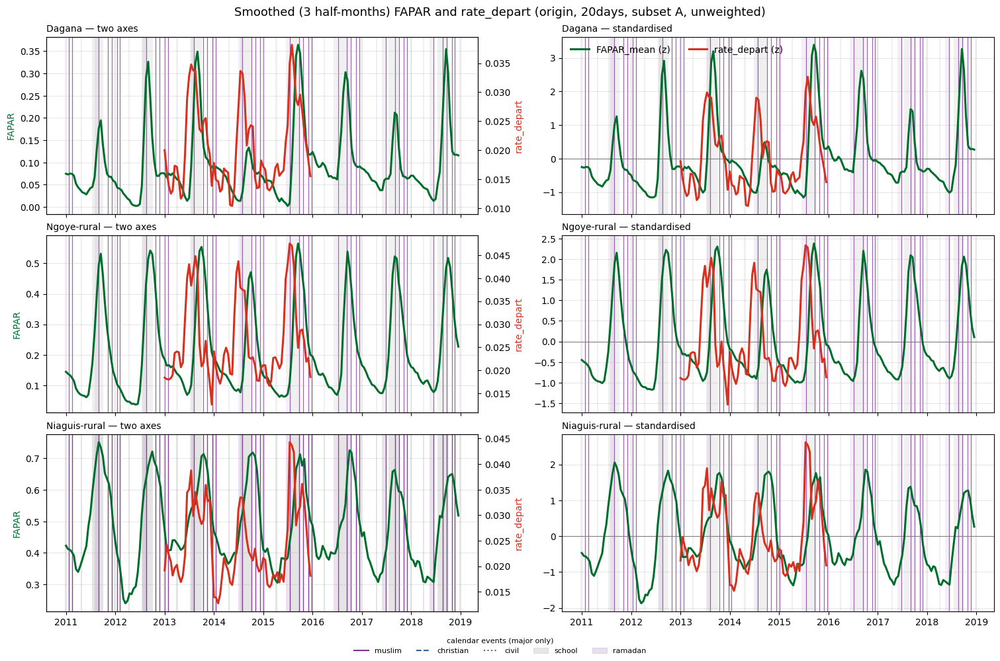

saved fig/smooth_together_N_depart.png


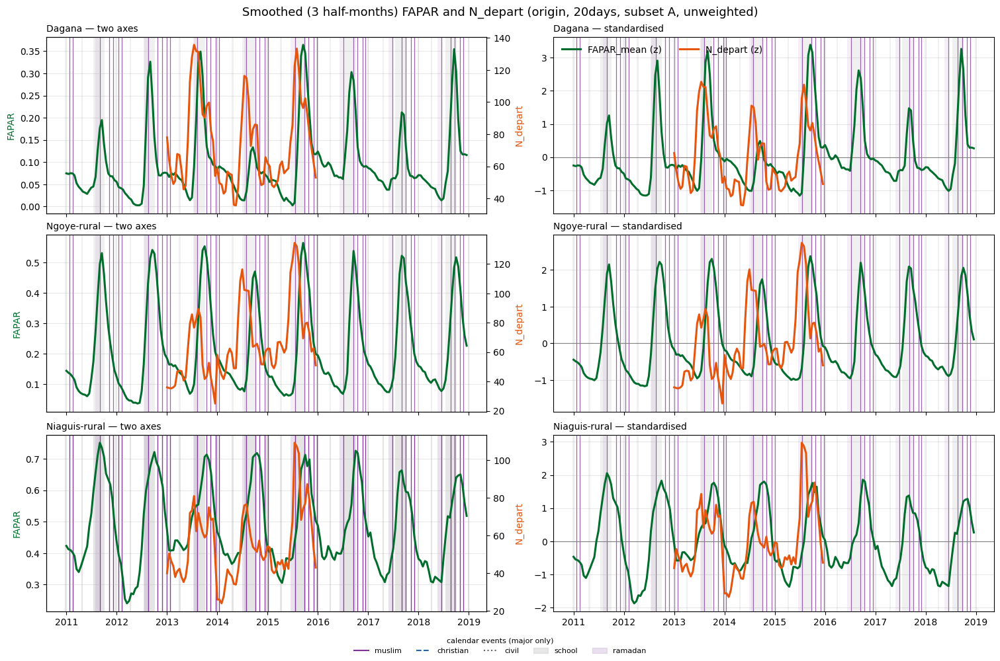

saved fig/smooth_together_N_return.png


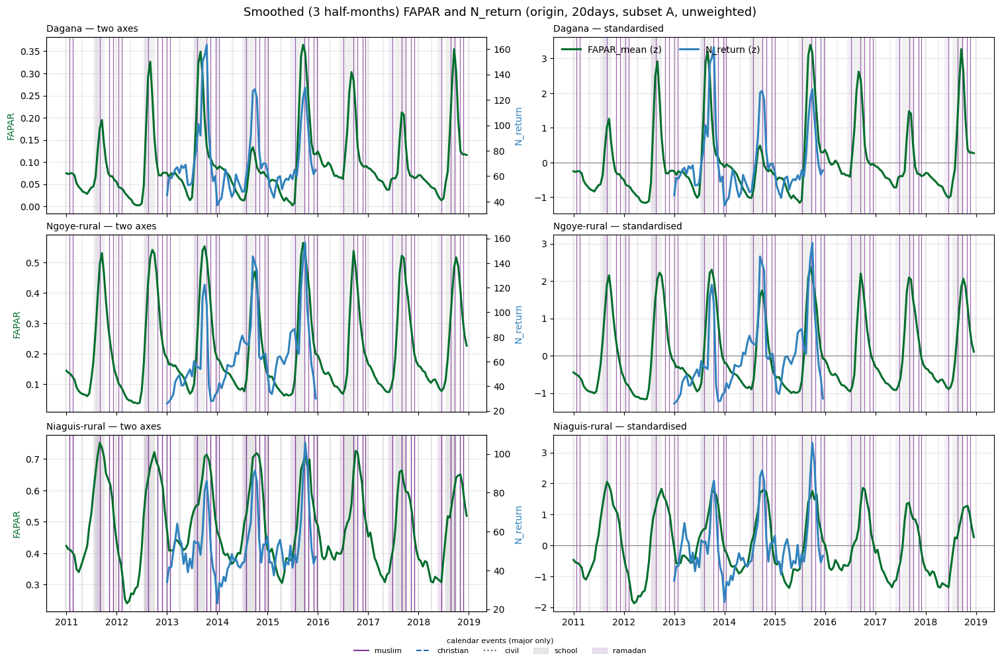

saved fig/smooth_together_N_migrants.png


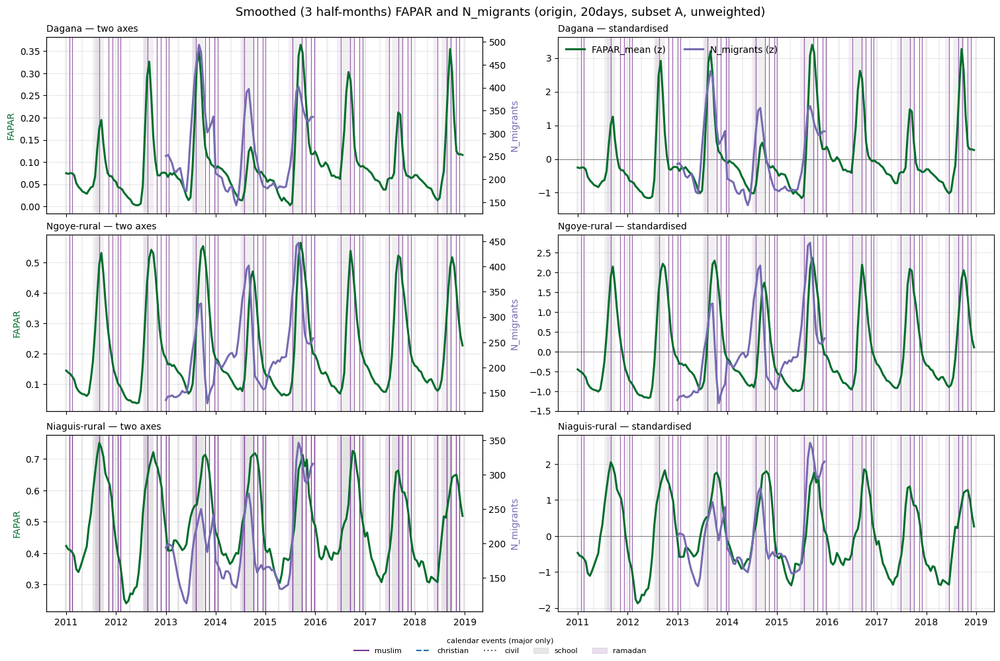

In [19]:
for m in METRICS:
    c = METRIC_COLORS.get(m, "#d7301f")
    n = len(SELECTED_IDS)
    fig, axes = plt.subplots(n, 2, figsize=(15, 3.1 * n + .6), sharex=True, constrained_layout=True, squeeze=False)
    for (ax, axz), zid in zip(axes, SELECTED_IDS):
        d = panel[panel.norm_id == zid].sort_values("period").set_index("period")
        f, y = smooth(d[MAIN]), smooth(d[m])
        ax.plot(d.index, f, color="#006d2c", lw=2.2); ax.set_ylabel("FAPAR", color="#006d2c"); ax.grid(alpha=.3)
        ax2 = ax.twinx(); ax2.plot(d.index, y, color=c, lw=2.2); ax2.set_ylabel(m, color=c)
        ax.set_title(f"{names.get(zid, zid)} — two axes", loc="left", fontsize=10)
        axz.axhline(0, color="grey", lw=.8)
        axz.plot(d.index, zscore(f), color="#006d2c", lw=2.2, label=f"{MAIN} (z)")
        axz.plot(d.index, zscore(y), color=c, lw=2.2, label=f"{m} (z)")
        axz.set_title(f"{names.get(zid, zid)} — standardised", loc="left", fontsize=10); axz.grid(alpha=.3)
        mark_events(ax); mark_events(axz)
    axes[0, 1].legend(frameon=False, ncol=2, loc="upper left")
    mark_events(axes[-1, 0], legend=True)
    fig.suptitle(f"Smoothed ({SMOOTH_WINDOW} half-months) FAPAR and {mlabel(m)}", fontsize=13)
    save(fig, f"smooth_together_{m}"); plt.show()

### National view
Mean `FAPAR_mean` across zones (with the inter-zone 10–90 % range) and the **sum** of each metric across zones.

saved fig/national.png


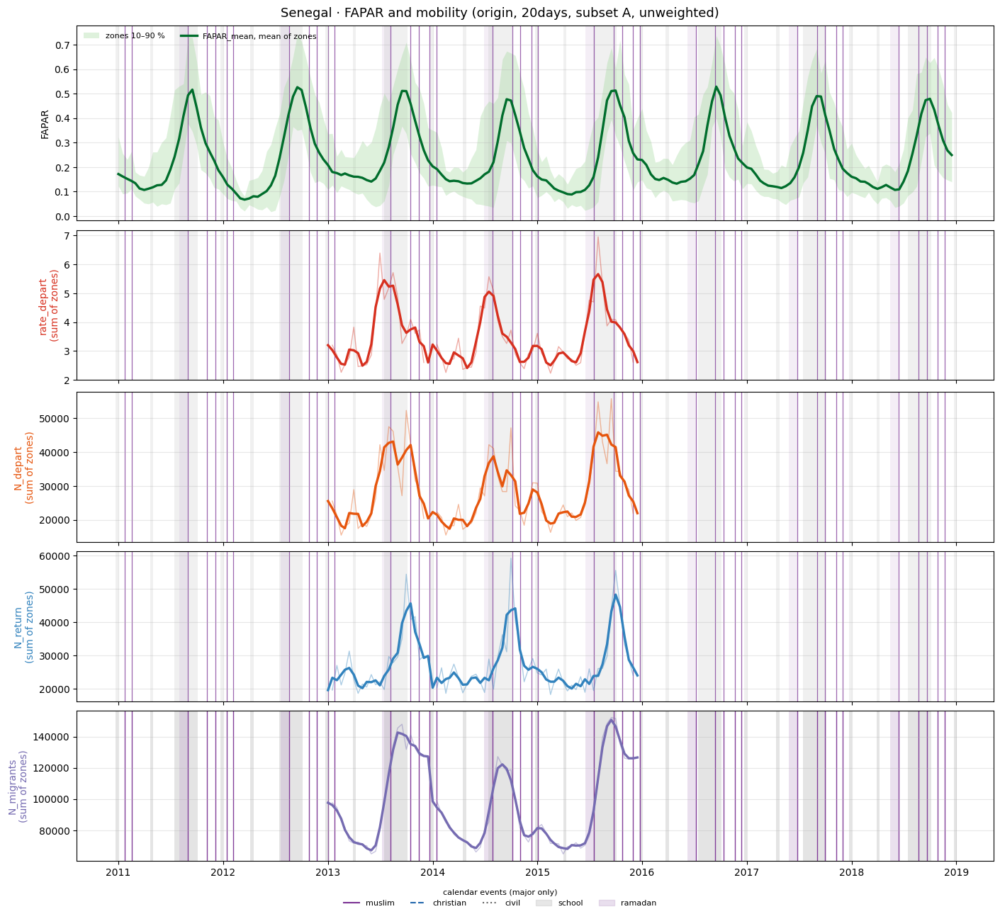

In [20]:
nat = panel.groupby("period").agg(fapar=(MAIN, "mean"),
                                  f10=(MAIN, lambda s: s.quantile(.1)), f90=(MAIN, lambda s: s.quantile(.9)),
                                  **{m: (m, lambda s: s.sum(min_count=1)) for m in METRICS})
fig, axs = plt.subplots(1 + len(METRICS), 1, figsize=(14, 2.4 * (1 + len(METRICS)) + .8), sharex=True,
                        constrained_layout=True, gridspec_kw={"height_ratios": [1.3] + [1] * len(METRICS)})
axs[0].fill_between(nat.index, nat.f10, nat.f90, color="#a1d99b", alpha=.35, lw=0, label="zones 10–90 %")
axs[0].plot(nat.index, smooth(nat.fapar), color="#006d2c", lw=2.4, label=f"{MAIN}, mean of zones")
axs[0].set_ylabel("FAPAR"); axs[0].grid(alpha=.3); axs[0].legend(frameon=False, ncol=2, loc="upper left", fontsize=8)
for ax, m in zip(axs[1:], METRICS):
    c = METRIC_COLORS.get(m, "#d7301f")
    ax.plot(nat.index, nat[m], color=c, lw=1, alpha=.4)
    ax.plot(nat.index, smooth(nat[m]), color=c, lw=2.4)
    ax.set_ylabel(f"{m}\n(sum of zones)", color=c); ax.grid(alpha=.3)
for i, ax in enumerate(axs):
    mark_events(ax, label_window=MOB_WINDOW if i == 1 else None)
mark_events(axs[-1], legend=True)
fig.suptitle(f"Senegal · FAPAR and mobility ({FLOW}, {SPAN}, subset {SUBSET}, {WEIGHT})", fontsize=13)
save(fig, "national"); plt.show()

### Sliding-window and lagged correlation (exploratory)
Left: correlation inside a moving window of `CORR_WINDOW` half-months. Right: correlation of **FAPAR at t** with
**mobility at t + lag** (positive lag = mobility after FAPAR; negative = mobility before). Only the CDR years
(≈ 3 seasons) contribute, so seasonality dominates — these are pointers, not results.

saved fig/correlation_rate_depart.png


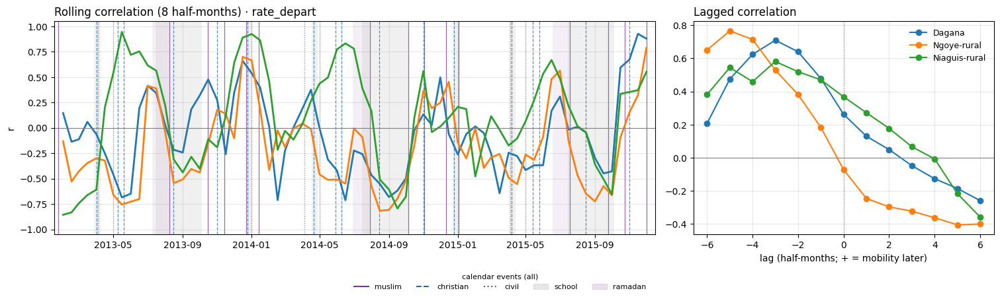

saved fig/correlation_N_depart.png


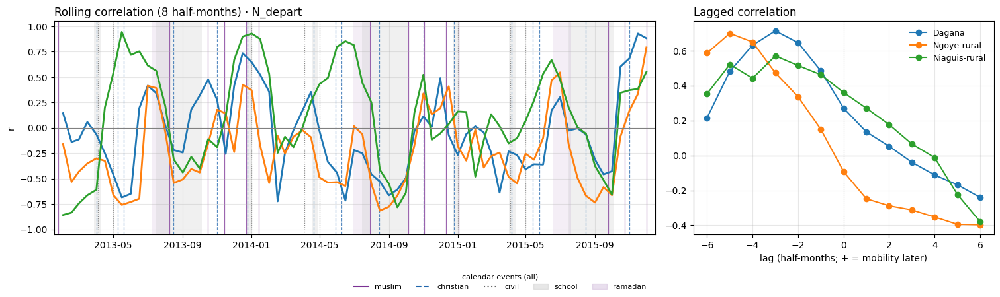

saved fig/correlation_N_return.png


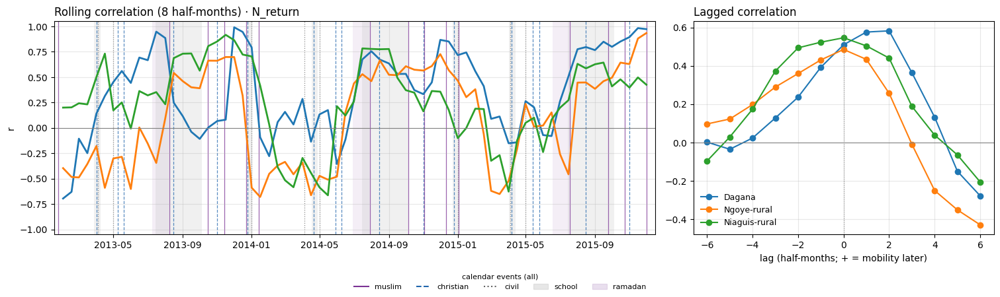

saved fig/correlation_N_migrants.png


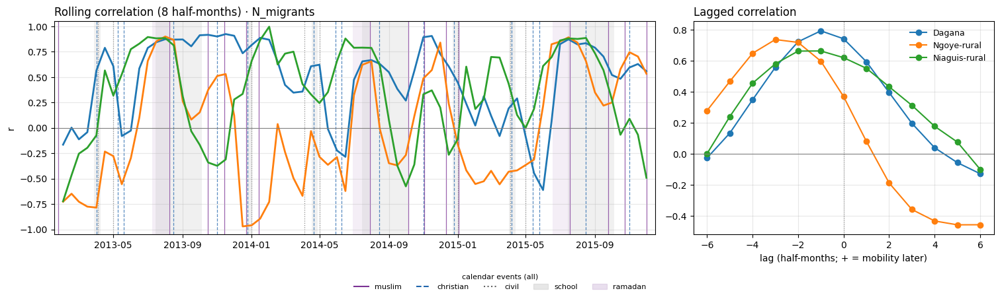

In [21]:
lags = list(range(-MAX_LAG, MAX_LAG + 1))
for m in METRICS:
    fig, (ax, axl) = plt.subplots(1, 2, figsize=(15, 4.4), constrained_layout=True,
                                  gridspec_kw={"width_ratios": [2, 1]})
    for zid in SELECTED_IDS:
        d = panel[panel.norm_id == zid].sort_values("period").set_index("period")
        rc = d[MAIN].rolling(CORR_WINDOW, center=True, min_periods=CORR_WINDOW // 2 + 1).corr(d[m])
        line, = ax.plot(rc.index, rc, lw=2, label=names.get(zid, zid))
        axl.plot(lags, [d[MAIN].corr(d[m].shift(-k)) for k in lags], marker="o", color=line.get_color(),
                 label=names.get(zid, zid))
    ax.set_xlim(*MOB_WINDOW); ax.axhline(0, color="grey", lw=.8); ax.set_ylim(-1.05, 1.05); ax.grid(alpha=.3)
    ax.set_title(f"Rolling correlation ({CORR_WINDOW} half-months) · {m}", loc="left"); ax.set_ylabel("r")
    mark_events(ax, label_window=MOB_WINDOW, legend=True, detail="all")
    axl.axhline(0, color="grey", lw=.8); axl.axvline(0, color="grey", lw=.8, ls=":"); axl.grid(alpha=.3)
    axl.set_xlabel("lag (half-months; + = mobility later)"); axl.set_title("Lagged correlation", loc="left")
    axl.legend(frameon=False, fontsize=9)
    save(fig, f"correlation_{m}"); plt.show()

### Correlation maps (all zones, all metrics)
Top row: same-period correlation of smoothed series. Bottom row: the **lag with the strongest absolute correlation**
(negative = mobility peaks before vegetation) — this separates timing differences from the strength of the link.

saved fig/correlation_maps.png


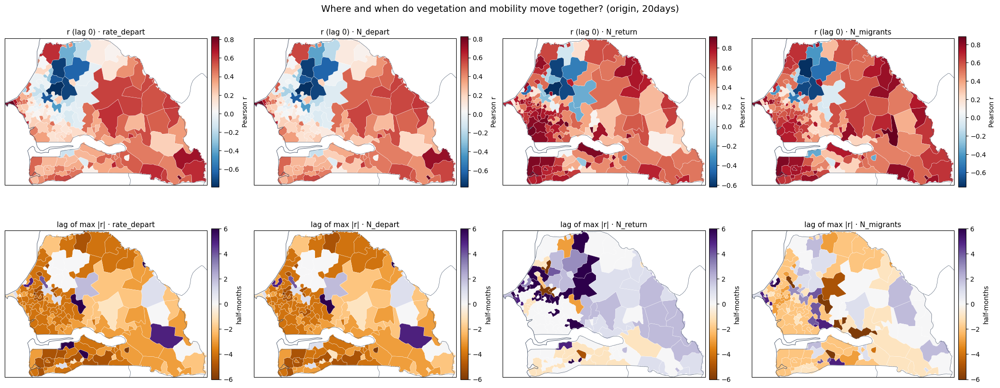

rate_depart                  N_depart                  N_return  \
               r0 best_lag  r_best       r0 best_lag  r_best       r0   
count      151.00   151.00  151.00   151.00   151.00  151.00   151.00   
mean         0.22    -2.77    0.64     0.22    -2.79    0.61     0.55   
std          0.31     2.39    0.40     0.31     2.27    0.40     0.34   
min         -0.79    -6.00   -0.79    -0.78    -6.00   -0.78    -0.62   
25%          0.05    -4.00    0.62     0.04    -4.00    0.58     0.43   
50%          0.28    -4.00    0.77     0.25    -4.00    0.76     0.66   
75%          0.45    -2.00    0.85     0.45    -2.00    0.85     0.77   
max          0.83     6.00    0.94     0.83     6.00    0.94     0.92   

                       N_migrants                   
      best_lag  r_best         r0 best_lag  r_best  
count   151.00  151.00     151.00   151.00  151.00  
mean      0.81    0.47       0.47    -0.89    0.55  
std       2.42    0.51       0.35     2.27    0.48  
min      -6.00   -0.74      -0.76    -6.00   -0.77  
25%       0.00    0.45       0.37    -2.00    0.53  
50%       0.00    0.69       0.58    -2.00    0.74  
75%       2.00    0.81       0.72     0.00    0.86  
max       6.00    0.92       0.89     6.00    0.96

In [22]:
def zone_stats(g, m):
    g = g.sort_values("period")
    f, y = smooth(g[MAIN]), smooth(g[m])
    rs = {k: f.corr(y.shift(-k)) for k in lags}
    best = max(rs, key=lambda k: -np.inf if pd.isna(rs[k]) else abs(rs[k]))
    return pd.Series({"r0": rs[0], "best_lag": best, "r_best": rs[best]})

ZSTATS = {m: panel.groupby("norm_id").apply(zone_stats, m, include_groups=False) for m in METRICS}
fig, _ = zone_panel([ZSTATS[m]["r0"] for m in METRICS] + [ZSTATS[m]["best_lag"] for m in METRICS],
                    [f"r (lag 0) · {m}" for m in METRICS] + [f"lag of max |r| · {m}" for m in METRICS],
                    ["RdBu_r"] * len(METRICS) + ["PuOr"] * len(METRICS),
                    labels=["Pearson r"] * len(METRICS) + ["half-months"] * len(METRICS),
                    ncols=len(METRICS), robust=False, size=4.2,
                    suptitle=f"Where and when do vegetation and mobility move together? ({FLOW}, {SPAN})")
save(fig, "correlation_maps"); plt.show()
pd.concat({m: ZSTATS[m].describe().round(2) for m in METRICS}, axis=1)

## 6 · Anomalies: taking the season out

Raw correlations mostly reflect two seasonal calendars. Here each series is compared with **its own usual value
for that half-month of the year**:

- FAPAR anomaly = value − mean of the same half-month over all cube years (2011–2018: a solid baseline).
- Mobility anomaly = value − mean of the same half-month over the CDR years (only ~3 years: a weak baseline,
  so treat mobility anomalies with care).

saved fig/anomalies_rate_depart.png


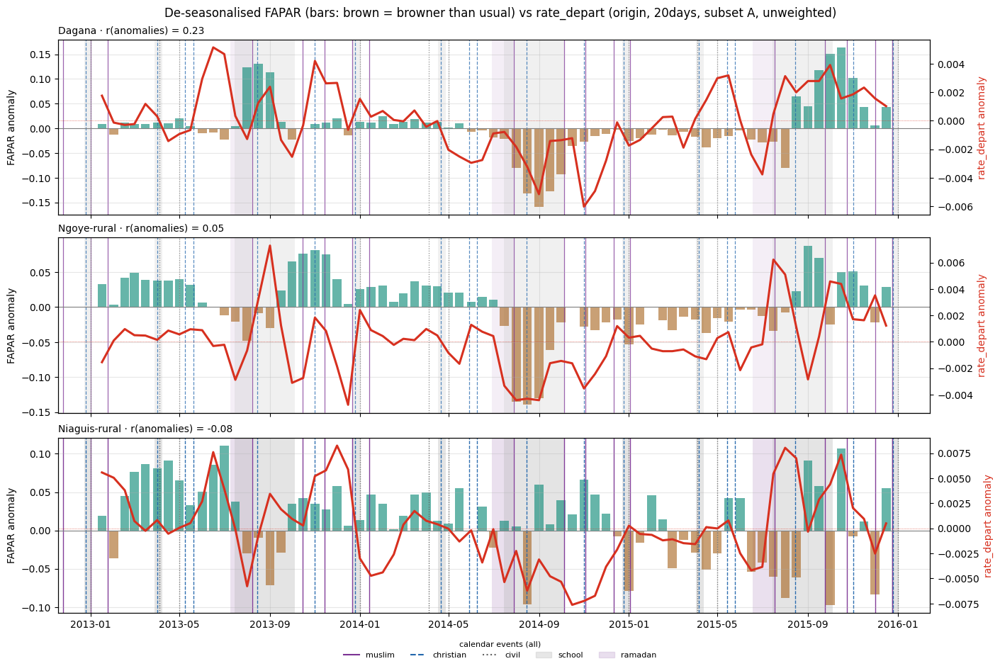

saved fig/anomalies_N_depart.png


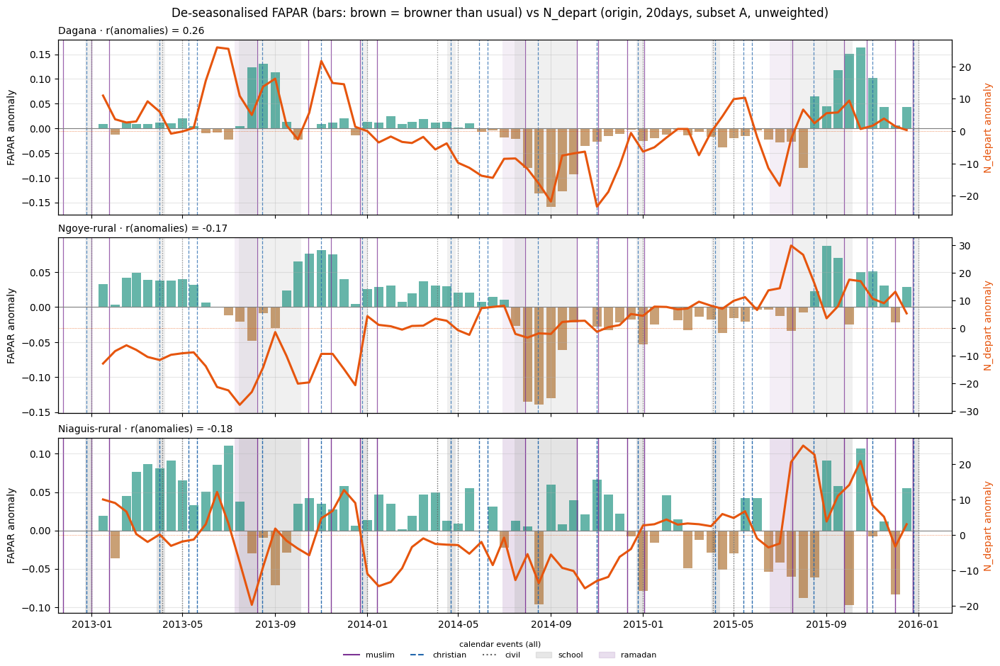

saved fig/anomalies_N_return.png


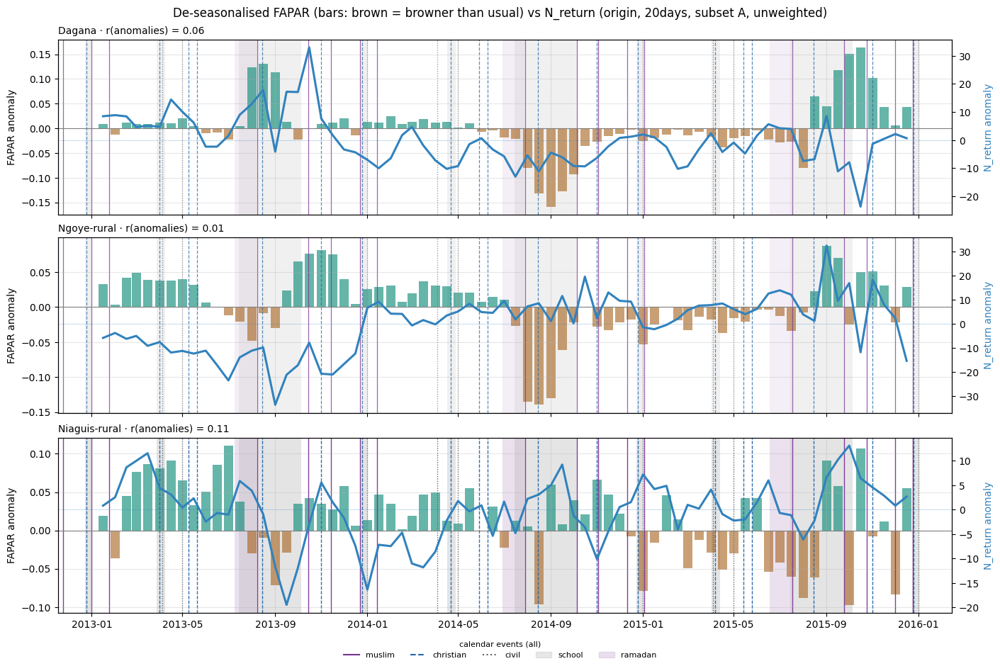

saved fig/anomalies_N_migrants.png


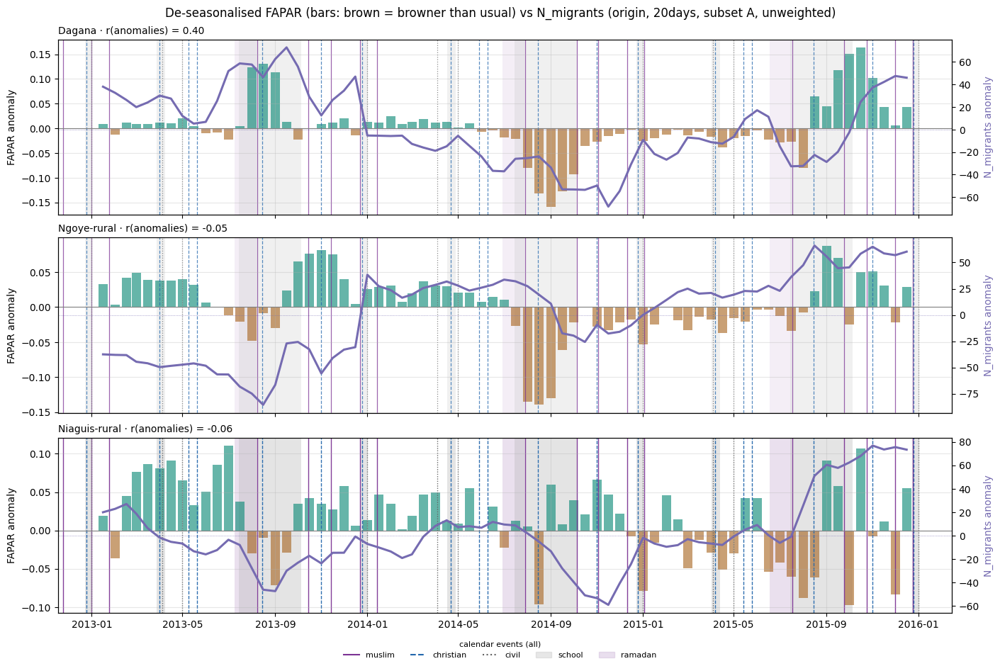

In [23]:
panel["hm"] = panel.period.dt.strftime("%m-%d")          # half-month of the year
panel[f"{MAIN}_anom"] = panel[MAIN] - panel.groupby(["norm_id", "hm"])[MAIN].transform("mean")
for m in METRICS:
    panel[f"{m}_anom"] = panel[m] - panel.groupby(["norm_id", "hm"])[m].transform("mean")

for m in METRICS:
    c = METRIC_COLORS.get(m, "#d7301f")
    n = len(SELECTED_IDS)
    fig, axes = plt.subplots(n, 1, figsize=(14, 2.9 * n + .6), sharex=True, constrained_layout=True, squeeze=False)
    for ax, zid in zip(axes[:, 0], SELECTED_IDS):
        d = panel[(panel.norm_id == zid) & panel.period.between(*MOB_WINDOW)].sort_values("period").set_index("period")
        ax.bar(d.index, d[f"{MAIN}_anom"], width=12, color=np.where(d[f"{MAIN}_anom"] < 0, "#a6611a", "#018571"),
               alpha=.6, label=f"{MAIN} anomaly")
        ax.set_ylabel("FAPAR anomaly"); ax.axhline(0, color="grey", lw=.8); ax.grid(alpha=.3)
        ax2 = ax.twinx()
        ax2.plot(d.index, smooth(d[f"{m}_anom"]), color=c, lw=2.2, label=f"{m} anomaly (smoothed)")
        ax2.axhline(0, color=c, lw=.5, ls=":"); ax2.set_ylabel(f"{m} anomaly", color=c)
        r = d[f"{MAIN}_anom"].corr(d[f"{m}_anom"])
        ax.set_title(f"{names.get(zid, zid)} · r(anomalies) = {r:.2f}", loc="left", fontsize=10)
        mark_events(ax, label_window=MOB_WINDOW if ax is axes[0, 0] else None, detail="all")
    mark_events(axes[-1, 0], legend=True, detail="all")
    fig.suptitle(f"De-seasonalised FAPAR (bars: brown = browner than usual) vs {mlabel(m)}", fontsize=12)
    save(fig, f"anomalies_{m}"); plt.show()

### Year comparison: did weak green seasons bring more departures?
For each zone: rainy-season (Jul–Oct) mean FAPAR and mean mobility per CDR year, expressed as the difference from
the zone's 2013–2015 average (FAPAR as a difference, mobility as **% change**, so large and small zones are
comparable). A **negative slope** (browner year → more mobility) would be the signal to look for.

saved fig/year_comparison.png


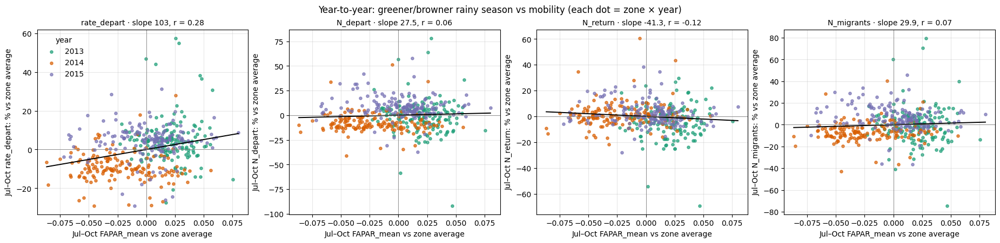

,FAPAR_mean,rate_depart,N_depart,N_return,N_migrants
year,,,,,
2013,0.022,3.963,-0.303,-2.919,-1.266
2014,-0.027,-9.944,-9.120,0.357,-6.601
2015,0.007,5.170,7.782,1.037,5.220


In [24]:
wet = panel[panel.period.dt.month.between(7, 10) & panel.period.between(*MOB_WINDOW)].copy()
wet["year"] = wet.period.dt.year
yr = wet.groupby(["norm_id", "year"])[[MAIN, *METRICS]].mean()
zmean = yr.groupby("norm_id").transform("mean")
dev = yr.copy()
dev[MAIN] = yr[MAIN] - zmean[MAIN]                                   # FAPAR: absolute difference
dev[METRICS] = 100 * (yr[METRICS] / zmean[METRICS].replace(0, np.nan) - 1)   # mobility: % vs zone average

fig, axes = plt.subplots(1, len(METRICS), figsize=(4.6 * len(METRICS), 4.4), constrained_layout=True, squeeze=False)
year_colors = dict(zip(sorted(dev.index.get_level_values("year").unique()), ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]))
for ax, m in zip(axes[0], METRICS):
    for y, g in dev.groupby(level="year"):
        ax.scatter(g[MAIN], g[m], s=14, alpha=.7, color=year_colors.get(y), label=str(y))
    ok = dev[[MAIN, m]].dropna()
    if len(ok) > 3:
        k, b = np.polyfit(ok[MAIN], ok[m], 1)
        xs = np.linspace(ok[MAIN].min(), ok[MAIN].max(), 50)
        ax.plot(xs, k * xs + b, color="black", lw=1.4)
        ax.set_title(f"{m} · slope {k:.3g}, r = {ok[MAIN].corr(ok[m]):.2f}", fontsize=10)
    ax.axhline(0, color="grey", lw=.6); ax.axvline(0, color="grey", lw=.6); ax.grid(alpha=.3)
    ax.set_xlabel(f"Jul–Oct {MAIN} vs zone average"); ax.set_ylabel(f"Jul–Oct {m}: % vs zone average")
axes[0, 0].legend(frameon=False, title="year")
fig.suptitle("Year-to-year: greener/browner rainy season vs mobility (each dot = zone × year)", fontsize=12)
save(fig, "year_comparison"); plt.show()
dev.groupby(level="year")[[MAIN, *METRICS]].median().round(3)   # median across zones

## Checks before interpreting

- **Period alignment:** `cdr_period` and the mobility `date` must use the same half-month start dates
  ("periods with mobility" above).
- **Window choice:** `SPAN` (20/30/60 days) changes the mobility signal; `SMOOTH_WINDOW` changes visual smoothness only.
- **Counts vs rates:** `N_*` grow with the number of observed users (and with zone population); `rate_*` adjust for
  observed users. Compare zones with rates, compare periods within a zone with either.
- **Seasonality and calendar:** mobility peaks can line up with Korité, Tabaski, Magal, school vacations or farm work
  rather than vegetation. Read the event markers before reading the correlations.
- **Event dates:** Islamic dates are computed (±1 day); school breaks are approximate — check the official calendars.
- **Short record:** three CDR years ≈ three seasonal cycles; anomalies and year comparisons are indicative only.
- **Pixel support:** small zones (cities) are covered by few cells; check hatched/missing zones.